In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("heart.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Column Names:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB

Missing Valu

In [4]:
if "HeartDisease" in df.columns:
    X = df.drop("HeartDisease", axis=1).copy()
else:
    X = df.copy()

print("Features Used for Clustering:")
print(X.columns.tolist())

Features Used for Clustering:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope']


In [5]:
categorical_columns = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
print(numerical_columns)

Categorical Columns:
['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

Numerical Columns:
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']


In [6]:
X = X.replace([np.inf, -np.inf], np.nan)

for column in numerical_columns:
    X[column] = X[column].fillna(X[column].median())

for column in categorical_columns:
    mode_values = X[column].mode()
    fill_value = (
        mode_values.iloc[0]
        if not mode_values.empty
        else "Unknown"
    )
    X[column] = X[column].fillna(fill_value)

print("Missing Values After Cleaning:")
print(X.isnull().sum())

Missing Values After Cleaning:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
dtype: int64


In [7]:
transformers = []

if numerical_columns:
    transformers.append(
        ("numerical", StandardScaler(), numerical_columns)
    )

if categorical_columns:
    transformers.append(
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
    sparse_threshold=0
)

X_processed = preprocessor.fit_transform(X)

print("Processed Dataset Shape:", X_processed.shape)

Processed Dataset Shape: (918, 20)


In [8]:
k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_processed)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_processed, labels)
    )

evaluation_df = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

evaluation_df.round(4)

,K,Inertia,Silhouette Score
0,2,6418.7175,0.1736
1,3,5686.5040,0.1784
2,4,5252.5217,0.1803
3,5,4968.0531,0.1300
4,6,4711.0209,0.1413
5,7,4529.2838,0.1288
6,8,4393.6668,0.1214
7,9,4247.3634,0.1235
8,10,4138.0535,0.1183


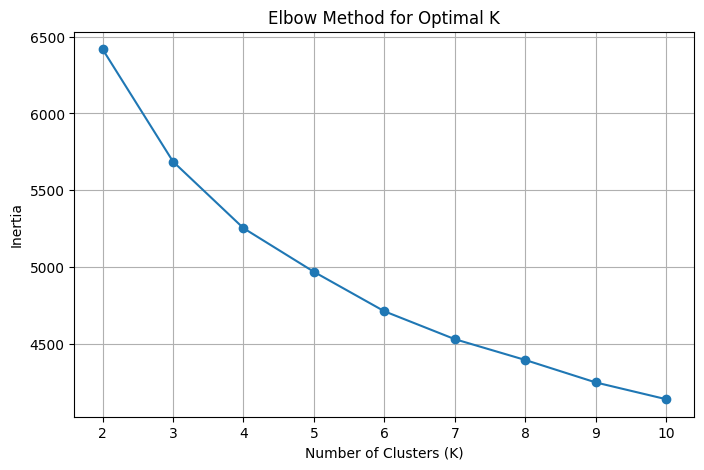

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

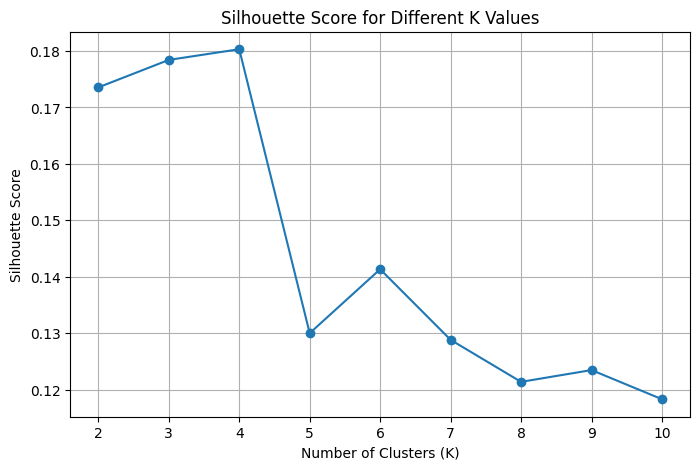

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [11]:
k = 3

kmeans_model = KMeans(
    n_clusters=k,
    init="k-means++",
    n_init=10,
    random_state=42
)

cluster_labels = kmeans_model.fit_predict(X_processed)

clustered_df = df.copy()
clustered_df["Cluster"] = cluster_labels

print("K-MEANS CLUSTERING")
print("------------------")
print("Number of Clusters:", k)
print("Inertia:", round(kmeans_model.inertia_, 4))

print(
    "Silhouette Score:",
    round(silhouette_score(X_processed, cluster_labels), 4)
)

K-MEANS CLUSTERING
------------------
Number of Clusters: 3
Inertia: 5686.504
Silhouette Score: 0.1784


In [12]:
print("First 10 Cluster Assignments:")

print(
    clustered_df[
        clustered_df.columns.tolist()
    ].head(10)
)

First 10 Cluster Assignments:
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   
5   39   M           NAP        120          339          0     Normal    170   
6   45   F           ATA        130          237          0     Normal    170   
7   54   M           ATA        110          208          0     Normal    142   
8   37   M           ASY        140          207          0     Normal    130   
9   48   F           ATA        120          284          0     Normal    120   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  Cluster  
0              N  

In [13]:
cluster_counts = (
    clustered_df["Cluster"]
    .value_counts()
    .sort_index()
)

print("Records in Each Cluster:")
print(cluster_counts)

Records in Each Cluster:
Cluster
0    208
1    323
2    387
Name: count, dtype: int64


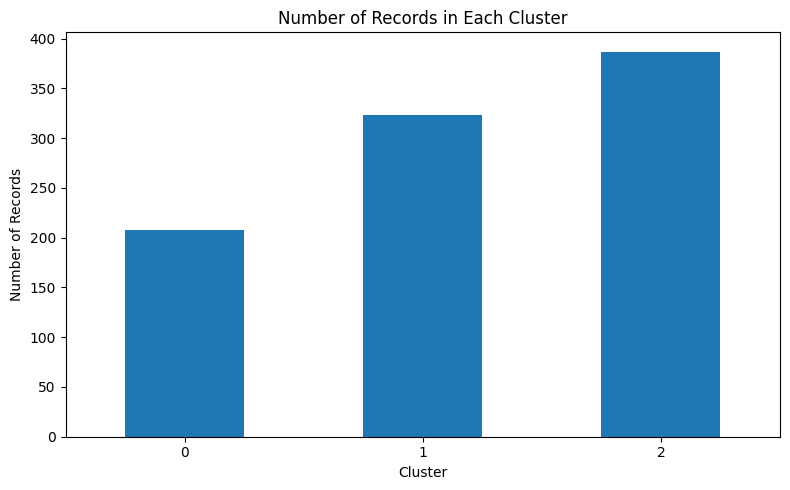

In [14]:
cluster_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Number of Records in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:
if numerical_columns:
    cluster_profiles = clustered_df.groupby("Cluster")[
        numerical_columns
    ].mean()

    print("Average Numerical Values per Cluster:")
    display(cluster_profiles.round(2))

Average Numerical Values per Cluster:


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak
Cluster,,,,,,
0,57.15,135.07,144.33,1.00,129.47,1.01
1,57.61,135.75,196.76,0.00,122.04,1.55
2,48.13,128.16,229.78,0.02,153.08,0.27


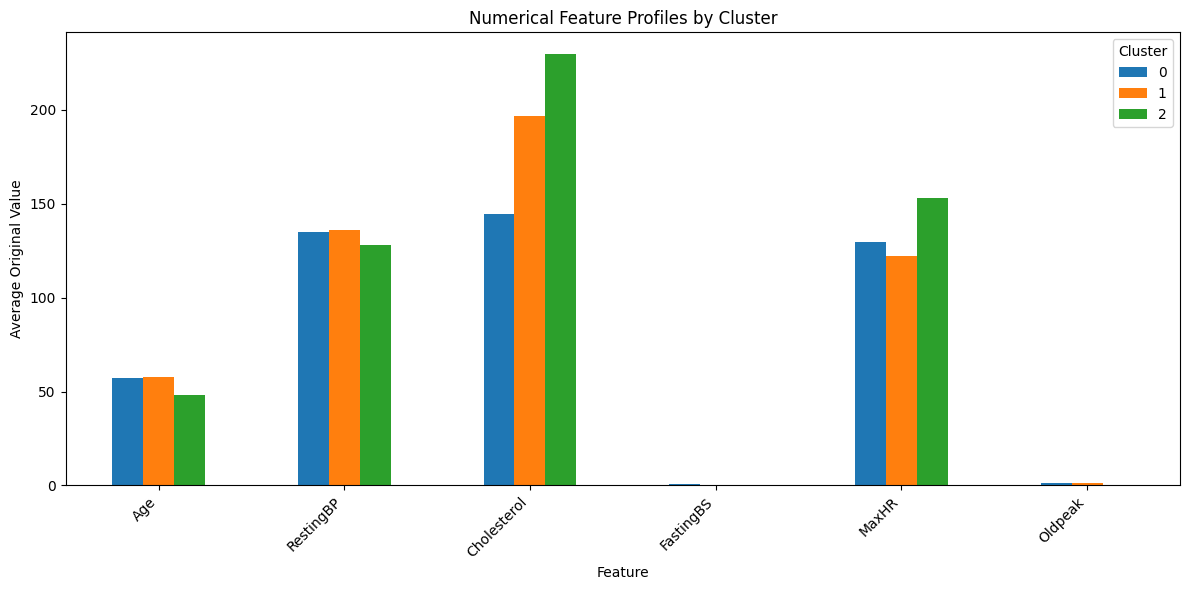

In [16]:
if numerical_columns:
    cluster_profiles.T.plot(
        kind="bar",
        figsize=(12, 6)
    )

    plt.title("Numerical Feature Profiles by Cluster")
    plt.xlabel("Feature")
    plt.ylabel("Average Original Value")
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="Cluster")
    plt.tight_layout()
    plt.show()

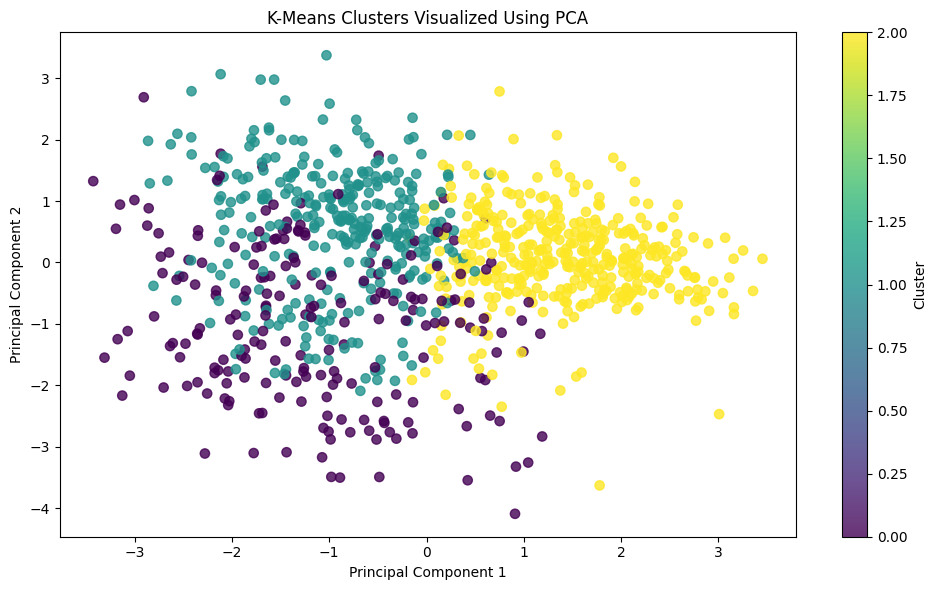

Variance represented by two PCA components: 40.47 %


In [17]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_processed)

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=45,
    alpha=0.8
)

plt.title("K-Means Clusters Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

print(
    "Variance represented by two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [18]:
output_file = "heart_clustered.csv"

clustered_df.to_csv(output_file, index=False)

print("Clustered Dataset Saved Successfully!")
print("Output File:", output_file)

Clustered Dataset Saved Successfully!
Output File: heart_clustered.csv


In [19]:
summary = (
    clustered_df.groupby("Cluster")
    .size()
    .reset_index(name="Number of Records")
)

summary["Percentage"] = (
    summary["Number of Records"]
    / len(clustered_df)
    * 100
).round(2)

print("FINAL CLUSTER SUMMARY")
print("=====================")

display(summary)

print("K-Means clustering completed successfully!")

FINAL CLUSTER SUMMARY


,Cluster,Number of Records,Percentage
0,0,208,22.66
1,1,323,35.19
2,2,387,42.16


K-Means clustering completed successfully!
